# Freq Filter Controller Logik
1. P_req aus power profile
2. Abgleich mit Convertern ratings (ggf. anfallende mismatches schon hier loggen)
3. Logik, um split aus P_bat und P_sc zu bestimmen, wobei der SC die high freq power spikes abfangen sollte
4. Battery wird mit P_bat gestepped, P_bat_actual wird aus battery.state.power ausgelesen
5. SC wird mit P_req - P_bat_actual gestepped, P_sc_actual wird aus sc.state.power ausgelesen
6. Jegliche over oder underflows werden gelogged

# Imports und Data

In [15]:
# ruff: disable[F401]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from simses.model.converter.fix_efficiency import FixedEfficiency
from simses.model.converter.sinamics import SinamicsS120

from hess import HybridController
from optimise import eval_configs, select_valid

%matplotlib inline
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

# ruff: enable[F401]

In [16]:
y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
p_bat_init = 0.0
y = y[1:]
x = np.diff(df.loc[df["segment_id"] == 1]["time_s"])

# Experiment 1: Known Cell Configs, efficient converter, Tau exploration

- bat_cell: type[CellType] = SonyLFP,
- sc_cell: type[CellType] = SCA3200,
- bat_series: int = 16,
- bat_parallel: int = 20,
- sc_series: int = 22,
- sc_parallel: int = 3
- converter_model: Callable[[], ConverterLossModel] = lambda: FixedEfficiency(1),

In [17]:
# creating configs from parameter space
from itertools import product

ps1 = {
    "tau": [0.001, 0.1, 1, 5, 10, 100, 250, 1000]
}

c1 = [
    dict(zip(ps1.keys(), combination))
    for combination in product(*ps1.values())
]

In [18]:
# running simulation for all options without logging everything
r1 = eval_configs(c1, x, y, p_bat_init, logging=False)

In [19]:
# here we'd filter invalid configs, but there are none
print(r1["error_fraction"].max())

1.0243809707125339e-19


In [20]:
# efficiency statistics for our configs
r1

,tau,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr
0,0.001,0.047357,0.000000e+00,5.839694,0.000000e+00,123.312237,0.000000
1,0.100,0.047236,0.000000e+00,5.824782,0.000000e+00,123.251297,1.607369
2,1.000,0.043801,0.000000e+00,5.401160,0.000000e+00,122.637029,23.318057
3,5.000,0.037334,0.000000e+00,4.603798,0.000000e+00,120.348706,50.496688
4,10.000,0.035209,0.000000e+00,4.341708,0.000000e+00,117.017878,54.217923
5,100.000,0.013947,0.000000e+00,1.719870,0.000000e+00,66.302872,63.937177
6,250.000,0.005736,0.000000e+00,0.707356,0.000000e+00,35.465176,87.847060
7,1000.000,0.011153,1.024381e-19,1.375246,1.263187e-17,30.591056,92.721181


In [21]:
# tau = 250 is a minimum
opt1 = r1.nsmallest(99, columns="loss_fraction")
opt1

,tau,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr
6,250.000,0.005736,0.000000e+00,0.707356,0.000000e+00,35.465176,87.847060
7,1000.000,0.011153,1.024381e-19,1.375246,1.263187e-17,30.591056,92.721181
5,100.000,0.013947,0.000000e+00,1.719870,0.000000e+00,66.302872,63.937177
4,10.000,0.035209,0.000000e+00,4.341708,0.000000e+00,117.017878,54.217923
3,5.000,0.037334,0.000000e+00,4.603798,0.000000e+00,120.348706,50.496688
2,1.000,0.043801,0.000000e+00,5.401160,0.000000e+00,122.637029,23.318057
1,0.100,0.047236,0.000000e+00,5.824782,0.000000e+00,123.251297,1.607369
0,0.001,0.047357,0.000000e+00,5.839694,0.000000e+00,123.312237,0.000000


In [22]:
# regenerate x best performing configs with full logging
c1_opt = [c1[i] for i in opt1.index]
r1_opt = eval_configs(
    c1_opt,
    x,
    y,
    p_bat_init,
    logging=True
)
r1_opt[0]["log"]

,p_bat_request,p_bat_cmd,p_bat_min,p_bat_max,p_bat_actual,p_bat_error,p_sc_request,p_sc_cmd,p_sc_min,p_sc_max,...,dE_total_error,e_total_error,loss_fraction,error_fraction,bat_v,bat_i,bat_soc,sc_v,sc_i,sc_soc
0,-1.381178,-1.381178,-15316.966413,3317.864086,-1.381178,0.0,-3452.255222,-3452.255222,-20000.0,20000.0,...,0.0,0.0,0.001818,0.0,52.701838,-0.026207,0.600000,50.068986,-68.949973,0.599496
1,-2.643528,-2.643528,-15316.966354,3317.864085,-2.643528,0.0,-3155.243272,-3155.243272,-20000.0,20000.0,...,0.0,0.0,0.001744,0.0,52.700989,-0.050161,0.600000,50.061002,-63.027969,0.599035
2,-3.785778,-3.785778,-15316.966243,3317.864081,-3.785778,0.0,-2855.052622,-2855.052622,-20000.0,20000.0,...,0.0,0.0,0.001672,0.0,52.700222,-0.071836,0.600000,50.054464,-57.038921,0.598618
3,-4.819591,-4.819591,-15316.966083,3317.864077,-4.819591,0.0,-2584.017009,-2584.017009,-20000.0,20000.0,...,0.0,0.0,0.001606,0.0,52.699527,-0.091454,0.600000,50.048532,-51.630226,0.598241
4,-5.739046,-5.739046,-15316.965880,3317.864070,-5.739046,0.0,-2298.176954,-2298.176954,-20000.0,20000.0,...,0.0,0.0,0.001544,0.0,52.698909,-0.108903,0.600000,50.044233,-45.922912,0.597905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1794,-1261.643635,-1261.643635,-15263.514393,3316.354894,-1261.643635,0.0,-1626.591165,-1626.591165,-20000.0,20000.0,...,0.0,0.0,0.005726,0.0,51.825273,-24.344177,0.588696,32.624847,-49.857434,0.042400
1795,-1262.383828,-1262.383828,-15263.461651,3316.353480,-1262.383828,0.0,-1850.112972,-1850.112972,-20000.0,20000.0,...,0.0,0.0,0.005729,0.0,51.824740,-24.358710,0.588685,32.604330,-56.744394,0.041985
1796,-1263.224543,-1263.224543,-15263.408877,3316.352064,-1263.224543,0.0,-2101.367057,-2101.367057,-20000.0,20000.0,...,0.0,0.0,0.005731,0.0,51.824136,-24.375217,0.588673,32.581094,-64.496517,0.041514
1797,-1264.187135,-1264.187135,-15263.356067,3316.350647,-1264.187135,0.0,-2405.999065,-2405.999065,-20000.0,20000.0,...,0.0,0.0,0.005734,0.0,51.823447,-24.394115,0.588662,32.553890,-73.908190,0.040973


tau = 250
 Battery SOC 0.5886506650212399
 Supercap SOC 0.04037581213614174
 Loss fraction 0.005736301325855265
 Error fraction 0.0


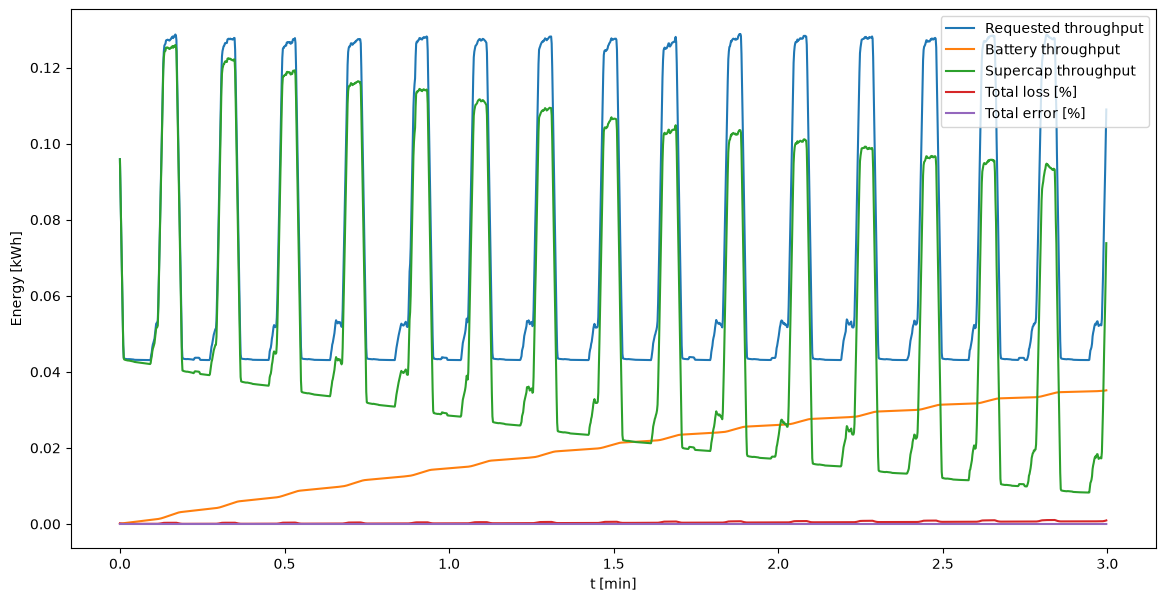

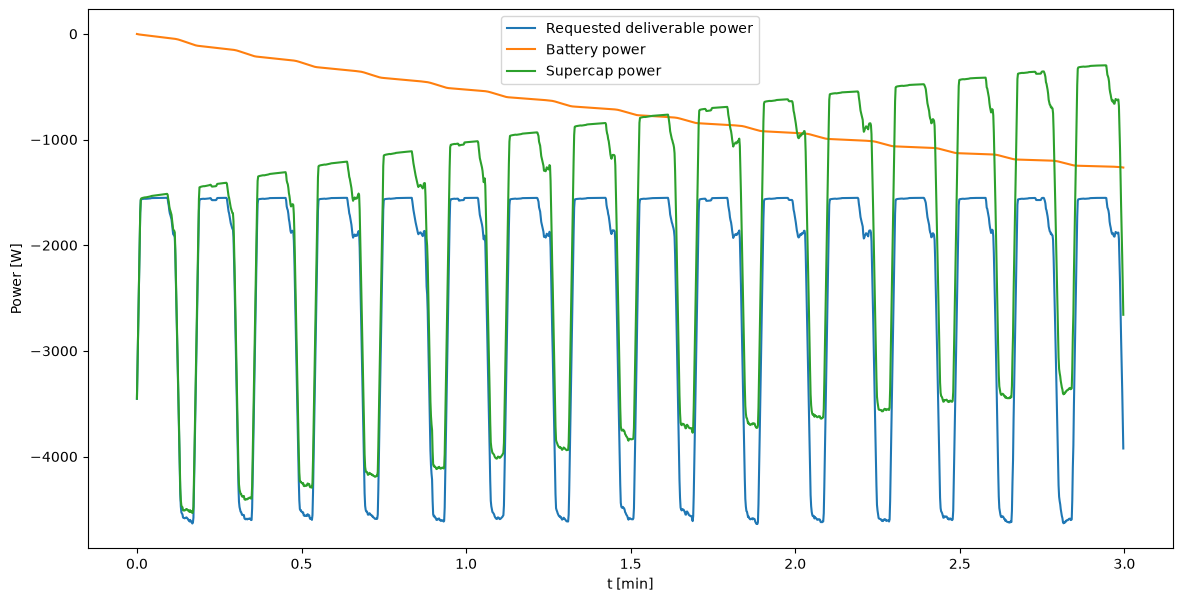

In [23]:
from plot import plot_simulation

# tau = 250 most efficient, but leans on sc almost exclusively -> high efficiency but sc empty after trial

i = 0
x_axis = r1_opt[i]["log"].index / 600

print( "tau =", r1_opt[i]["tau"])

plot_simulation(r1_opt, x_axis, i)

tau = 1000
 Battery SOC 0.5899885767190912
 Supercap SOC 6.443193599034171e-17
 Loss fraction 0.011152552709748721
 Error fraction 1.0243809707125339e-19


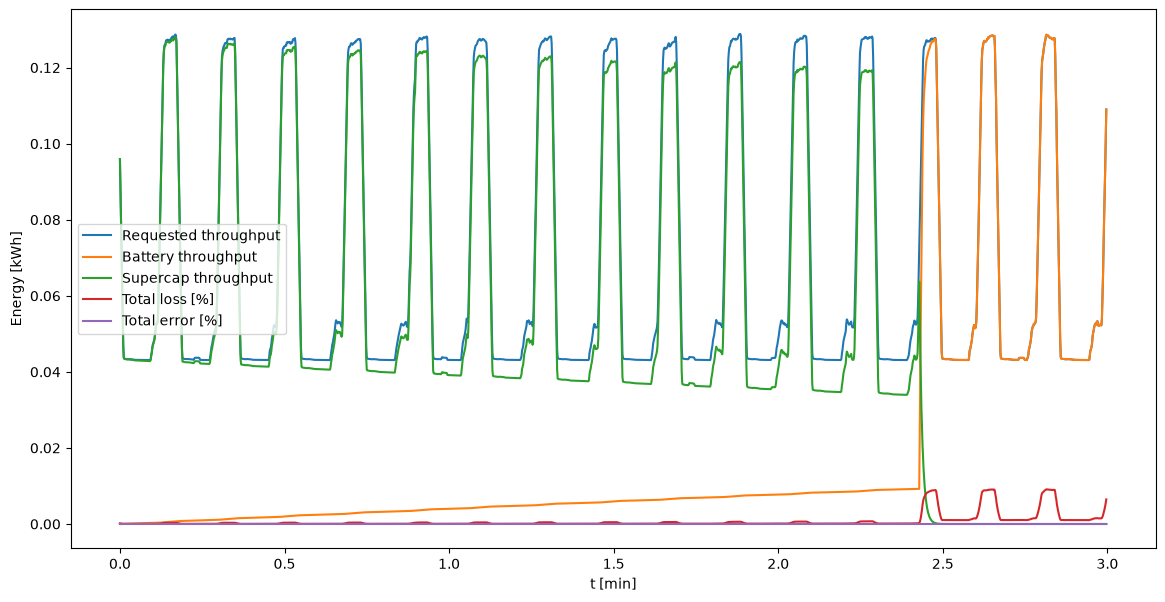

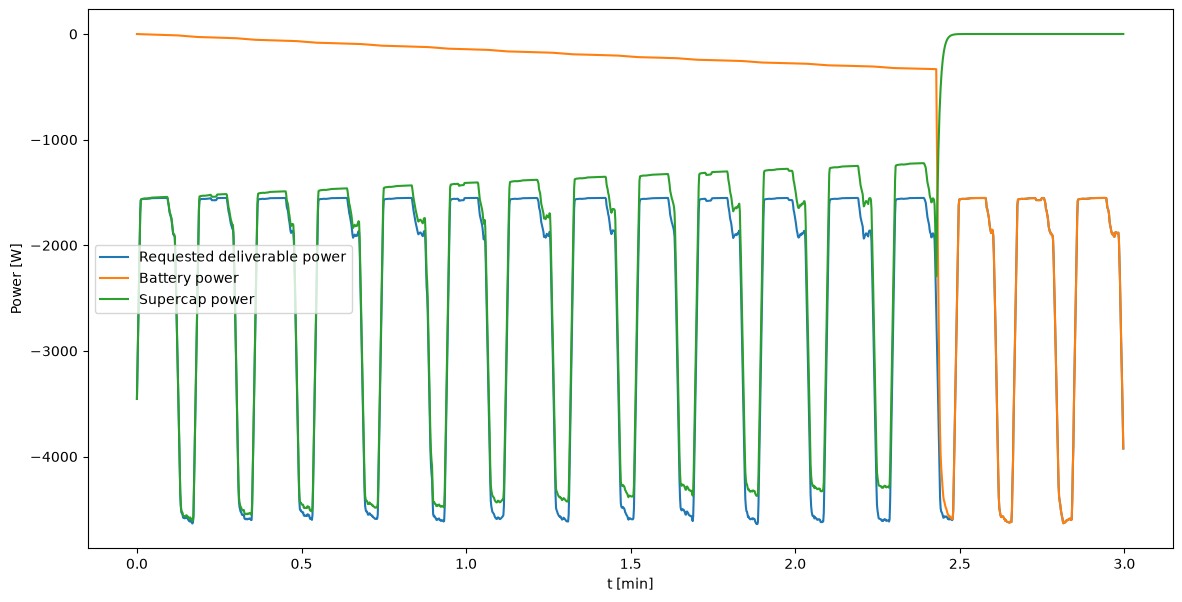

In [24]:
# tau = 1000 drains sc fully, battery has to take over -> still somehow 2nd most efficient


i = 1
x_axis = r1_opt[i]["log"].index / 600

print("tau =", r1_opt[i]["tau"])

plot_simulation(r1_opt, x_axis, i)

tau = 0.001
 Battery SOC 0.5592639248311638
 Supercap SOC 0.6
 Loss fraction 0.047356969105784914
 Error fraction 0.0


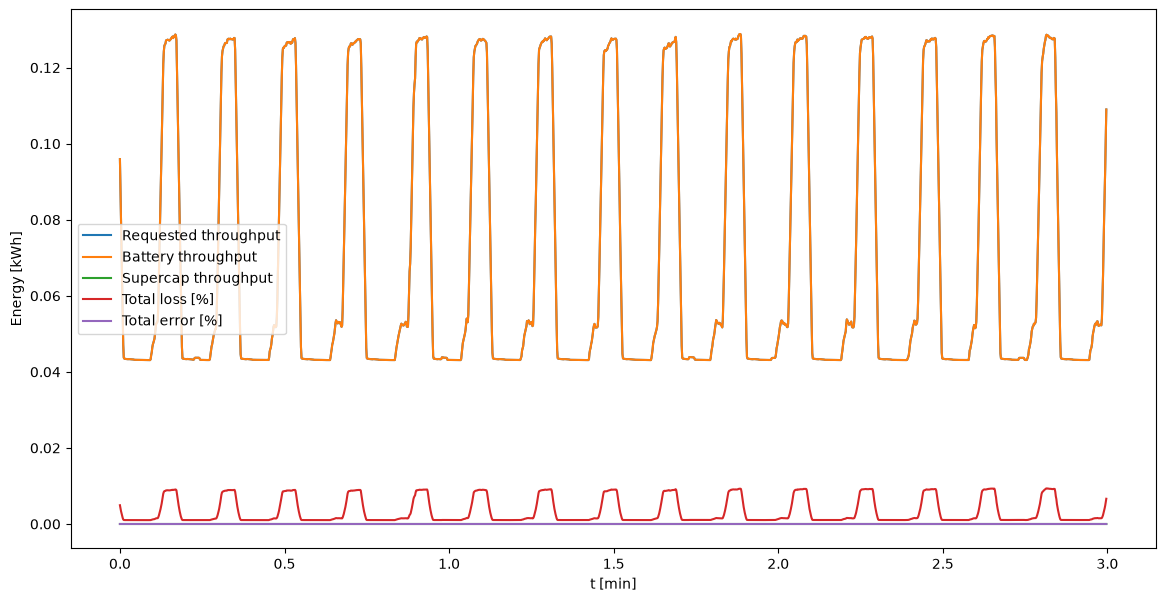

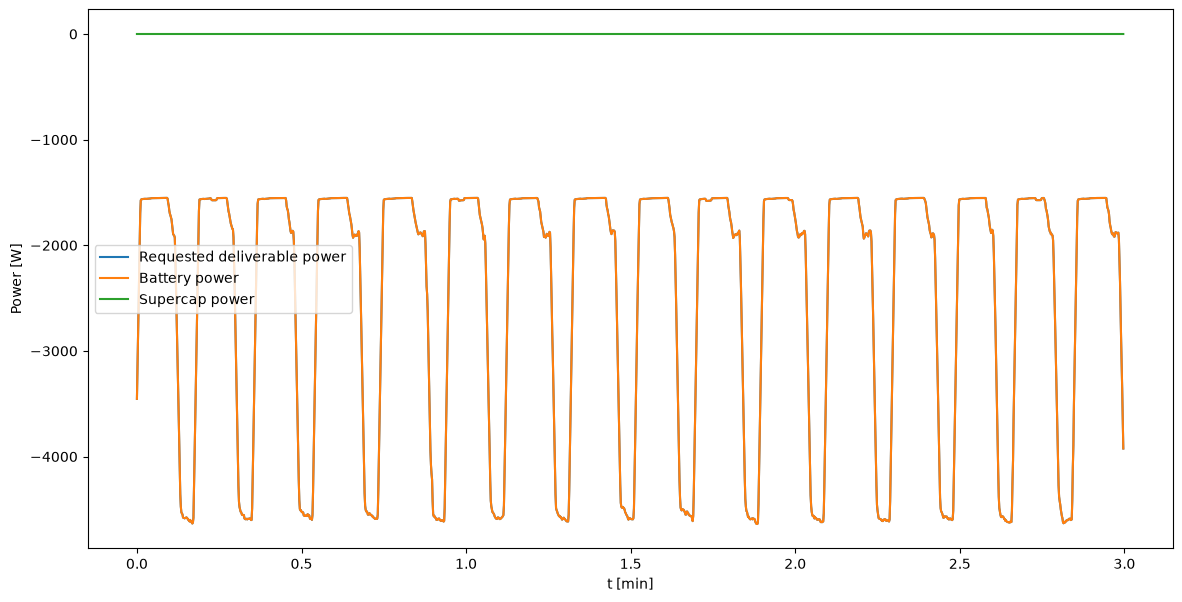

In [25]:
# tau = 0.001 => supercap basically not in use; least efficient

i = -1
x_axis = r1_opt[i]["log"].index / 600

print("tau =", r1_opt[i]["tau"])

plot_simulation(r1_opt, x_axis, i)

# Experiment 2: Set Tau, efficient converter, Cell config exploration
keep tau at 100 (slightly below the optimal 250, s.t. there's buffer for more battery heavy designs)

In [26]:
from itertools import product

ps2 = {
    "tau": [100],
    "bat_series": range(10, 30, 2),
    "bat_parallel": range(10,30,2),
    "sc_series": range(10, 30, 2),
    "sc_parallel": range(1,5,1)
}

c2 = [
    dict(zip(ps2.keys(), combination))
    for combination in product(*ps2.values())
]

len(c2)

4000

In [27]:
r2 = eval_configs(c2, x, y, p_bat_init, logging=False)

In [ ]:
# filtering invalid configs
print(r2["error_fraction"].max())
v2 = select_valid(r2, error_threshold=0.001)

3.585333397493643e-18


In [29]:
# generating secondary optimisation metric

v2["n_bat"] = v2["bat_series"] * v2["bat_parallel"]
v2["n_sc"] = v2["sc_series"] * v2["sc_parallel"]
v2["n_cells"] = v2["n_bat"] + v2["n_sc"]

In [30]:
from optimise import make_front
from plot import plot_pareto

f2 = make_front(v2, "n_cells", "loss_fraction")

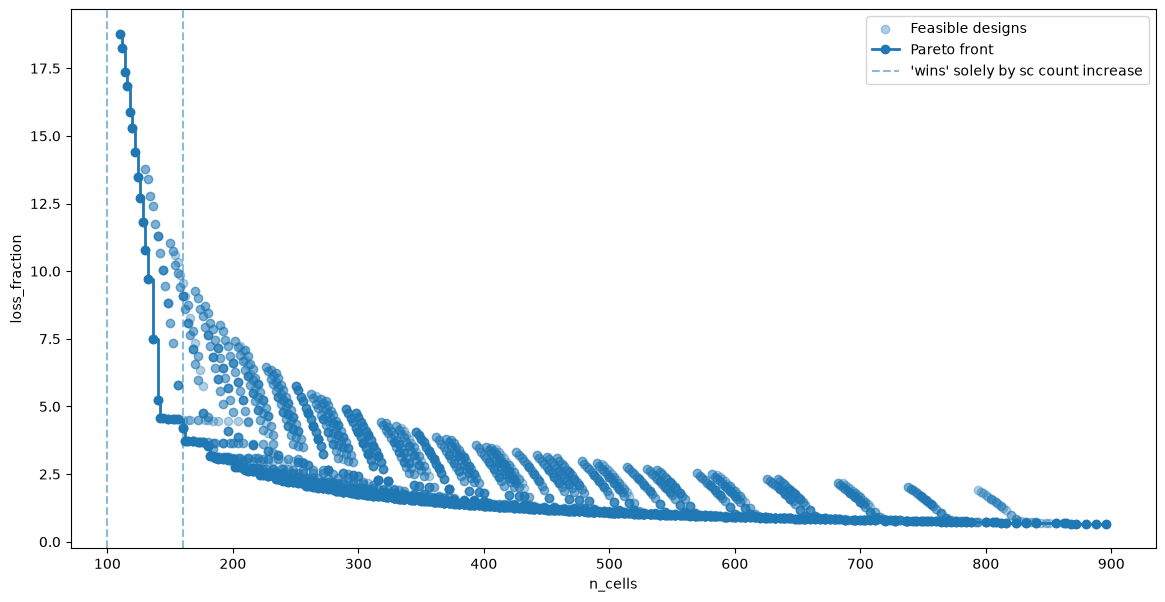

In [31]:
plot_pareto(v2, f2, "n_cells", "loss_fraction")

plt.axvline(x=100, alpha=0.5, linestyle="--", label="'wins' solely by sc count increase")
plt.axvline(x=160, alpha=0.5, linestyle="--")

plt.legend()

In [32]:
f2.loc[(f2["n_cells"] > 100) & (f2["n_cells"] < 160)]

,tau,bat_series,bat_parallel,sc_series,sc_parallel,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr,n_bat,n_sc,n_cells
0,100,10,10,10,1,0.187671,1.024381e-19,23.142144,1.263187e-17,110.157225,20.082824,100,10,110
4,100,10,10,12,1,0.182540,2.048762e-19,22.509392,2.526374e-17,107.309422,22.930627,100,12,112
8,100,10,10,14,1,0.173477,1.536571e-19,21.391810,1.894781e-17,104.507097,25.732952,100,14,114
12,100,10,10,16,1,0.168469,2.048762e-19,20.774285,2.526374e-17,101.671280,28.568769,100,16,116
16,100,10,10,18,1,0.158983,3.585333e-18,19.604501,4.421155e-16,98.863812,31.376237,100,18,118
1,100,10,10,10,2,0.152773,0.000000e+00,18.838820,0.000000e+00,96.033581,34.206468,100,20,120
24,100,10,10,22,1,0.144156,1.024381e-19,17.776198,1.263187e-17,93.224544,37.015505,100,22,122
28,100,10,10,24,1,0.134952,1.536571e-19,16.641272,1.894781e-17,90.402806,39.837243,100,24,124
32,100,10,10,26,1,0.126917,3.073143e-19,15.650448,3.789561e-17,87.581797,42.658252,100,26,126
9,100,10,10,14,2,0.118177,4.097524e-19,14.572619,5.052748e-17,84.766458,45.473591,100,28,128


In [33]:
f2.loc[(f2["n_cells"] > 160) & (f2["n_cells"] < 220)]

,tau,bat_series,bat_parallel,sc_series,sc_parallel,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr,n_bat,n_sc,n_cells
50,100,10,12,14,3,0.037376,0.0,4.608884,0.0,66.302872,63.937177,120,42,162
65,100,10,12,22,2,0.037257,0.0,4.594190,0.0,66.302872,63.937177,120,44,164
54,100,10,12,16,3,0.037066,0.0,4.570695,0.0,66.302872,63.937177,120,48,168
73,100,10,12,26,2,0.036920,0.0,4.552664,0.0,66.302872,63.937177,120,52,172
418,100,12,10,18,3,0.036859,0.0,4.545118,0.0,66.302872,63.937177,120,54,174
51,100,10,12,14,4,0.036804,0.0,4.538343,0.0,66.302872,63.937177,120,56,176
83,100,10,14,10,4,0.035284,0.0,4.350925,0.0,67.871029,62.369020,140,40,180
90,100,10,14,14,3,0.031747,0.0,3.914817,0.0,66.302872,63.937177,140,42,182
105,100,10,14,22,2,0.031628,0.0,3.900123,0.0,66.302872,63.937177,140,44,184
450,100,12,12,14,3,0.030838,0.0,3.802688,0.0,66.302872,63.937177,144,42,186


In [ ]:
# import plotly.express as px

# fig = px.scatter(
#     v2,
#     x="n_cells",
#     y="loss_fraction",
#     color="sc_fraction",
#     color_continuous_scale="Viridis",
#     hover_data=[
#         "bat_series",
#         "bat_parallel",
#         "sc_series",
#         "sc_parallel",
#         "n_bat",
#         "n_sc",
#         # "tau",
#     ],
# )

# fig.update_traces(
#     marker={
#         "opacity" : 0.55,
#         "size" : 10
#         }
# )

# fig.update_layout(
#     width=1000,
#     height=600,
#     template="presentation",
#     margin={"l": 70, "r": 20, "t": 20, "b": 50},
#     coloraxis_colorbar={
#         # "thickness": 15,
#         # "len": 0.85,
#         "xpad": 0,
#     }
# )

# fig.update_xaxes(automargin=False)
# fig.update_yaxes(automargin=False)

# fig.show()

ValueError: Value of 'color' is not the name of a column in 'data_frame'. Expected one of ['tau', 'bat_series', 'bat_parallel', 'sc_series', 'sc_parallel', 'loss_fraction', 'error_fraction', 'e_total_loss', 'e_total_error', 'e_bat_thr', 'e_sc_thr', 'n_bat', 'n_sc', 'n_cells'] but received: sc_fraction

## Preliminary findings
- going from (n_bat = 100, n_sc = 10) to (n_bat = 100, n_sc = 40) major performance increase from 18% loss to 5%
    - sc-limited stage for tau = 100
- specifically how we get there doesn't seem to matter much (sc_series = 14, sc_parallel = 3, n_sc = 42, loss = 4.5%) vs. (sc_series = 20, sc_parallel = 2, n_sc=40, loss=5.2%) occupy pretty much the same space; same with n_sc = 32 and n_sc = 30
- BUT after reaching n_sc = 40 we get diminishing results, and going from (sc_series = 14, sc_parallel = 3, n_sc = 42) to (sc_series = 20, sc_parallel = 3, n_sc = 60) has basically same loss of 4.5%
- Only then, does increasing battery count matter, and the optimal strategy becomes: increment sc_count until 60, increment battery_count, reset sc_count, start over
- It doesnt seem to matter whether we increase n_bat_series or parallel, just the count matters

=> if serial vs parallel really doesnt matter, optimisation boils down to (n_bat, n_sc, tau)

## Next steps
- investigate what happens in the sc-limited stage